# Task 2 — Baseline Models & Backtesting

Runs SeasonalNaive, ETS, and ARIMA through the rolling-origin backtest
harness and produces a comparison table (WAPE, RMSSE, MAE).

**Pre-requisite:** `data/processed/m5_long.parquet` exists.

In [3]:
import os

os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'   # silence the hint

from pathlib import Path

import mlflow
import pandas as pd
import plotly.express as px

from m5forecast.evaluation.backtest import Backtester, RollingOriginSplitter
from m5forecast.models.baselines import ARIMAForecaster, ETSForecaster, SeasonalNaive

ROOT = Path("..").resolve()
PARQUET = ROOT / "data" / "processed" / "m5_long.parquet"
assert PARQUET.exists(), "Run `make data` first"

mlflow.set_tracking_uri(r"sqlite:///C:\Users\isha\OneDrive\Documents\TimeSeries\m5-forecasting-platform\mlflow.db")
mlflow.set_experiment("m5-baselines")
print("MLflow OK — tracking to:", mlflow.get_tracking_uri())


MLflow OK — tracking to: sqlite:///C:\Users\isha\OneDrive\Documents\TimeSeries\m5-forecasting-platform\mlflow.db


In [4]:
df = pd.read_parquet(PARQUET)

# Aggregate to store level — fast, interpretable
store_agg = (
    df.groupby(["date", "store_id"])["sales"]
    .sum()
    .reset_index()
    .sort_values("date")
)

STORES = store_agg["store_id"].unique()
print("Stores:", STORES)

C:\Users\isha\AppData\Local\Temp\ipykernel_19692\887266825.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["date", "store_id"])["sales"]


Stores: ['CA_1', 'TX_1', 'WI_1']
Categories (3, object): ['CA_1', 'TX_1', 'WI_1']


In [5]:
HORIZON = 28
N_FOLDS = 4

splitter = RollingOriginSplitter(n_folds=N_FOLDS, horizon=HORIZON, min_train=365)
bt = Backtester(splitter=splitter)

models = {
    "seasonal_naive": SeasonalNaive(seasonality=7),
    "ets_add": ETSForecaster(trend="add", seasonal="add", seasonal_periods=7),
    "arima_211": ARIMAForecaster(order=(2, 1, 1)),
}

all_results = {}

for store in STORES:
    series = (
        store_agg[store_agg["store_id"] == store]
        .set_index("date")["sales"]
        .sort_index()
    )
    print(f"\n=== {store} ===")

    with mlflow.start_run(run_name=f"baselines_{store}"):
        mlflow.log_param("store", store)
        mlflow.log_param("horizon", HORIZON)
        mlflow.log_param("n_folds", N_FOLDS)

        comparison = bt.compare_models(models, series)
        all_results[store] = comparison
        print(comparison.to_string())

        for model_name, row in comparison.iterrows():
            mlflow.log_metric(f"{model_name}_wape", row["wape"])
            mlflow.log_metric(f"{model_name}_rmsse", row["rmsse"])


=== CA_1 ===


C:\Users\isha\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\isha\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\isha\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\isha\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_par

                    wape     rmsse         mae        rmse
model                                                     
ets_add         0.064553  0.441895  293.978851  381.784314
seasonal_naive  0.094714  0.630202  429.187500  544.497802
arima_211       0.154123  1.056592  702.069161  913.019379

=== TX_1 ===


C:\Users\isha\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\isha\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\isha\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\isha\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start

                    wape     rmsse         mae        rmse
model                                                     
ets_add         0.089280  0.605072  297.875093  361.531171
seasonal_naive  0.104925  0.697689  349.633929  416.867050
arima_211       0.129214  0.945431  431.156272  564.860451

=== WI_1 ===
                    wape     rmsse         mae        rmse
model                                                     
ets_add         0.078225  0.554070  301.642280  392.422350
seasonal_naive  0.108912  0.780785  419.285714  553.914309
arima_211       0.188104  1.272077  724.255366  901.379072


In [7]:
# Combined comparison across all stores
combined = (
    pd.concat(all_results, names=["store", "model"])
    .reset_index()
    .groupby("model")[["wape", "rmsse", "mae"]]
    .mean()
    .sort_values("wape")
)
print("\nAverage across all stores:")
combined


Average across all stores:


,wape,rmsse,mae
model,,,
ets_add,0.077353,0.533679,297.832074
seasonal_naive,0.102850,0.702892,399.369048
arima_211,0.157147,1.091367,619.160266


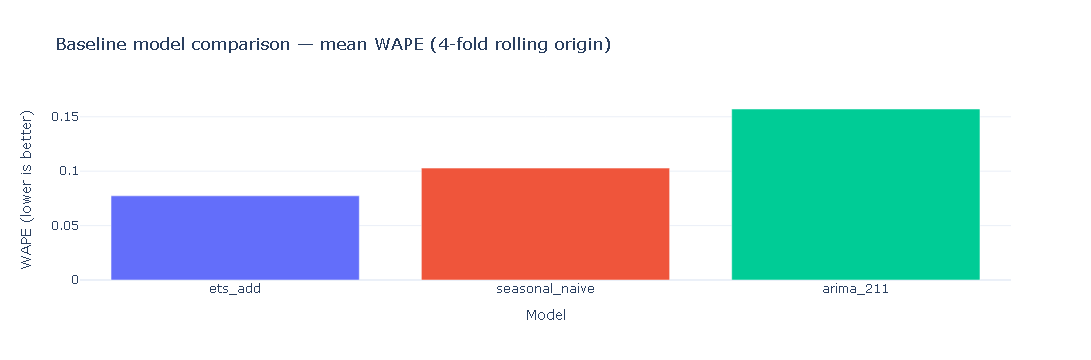

In [8]:
fig = px.bar(
    combined.reset_index(),
    x="model", y="wape",
    title="Baseline model comparison — mean WAPE (4-fold rolling origin)",
    labels={"wape": "WAPE (lower is better)", "model": "Model"},
    color="model",
)
fig.update_layout(template="plotly_white", showlegend=False)
fig.write_image(str(ROOT / "reports" / "figures" / "baseline_comparison.png"))
fig.show()

## Conclusions

**Results (mean WAPE across CA_1, TX_1, WI_1 — 4-fold rolling origin, 28-day horizon):**

| Model          | Avg WAPE | Avg RMSSE | Key observation |
|----------------|----------|-----------|-----------------|
| ETS (additive) | 0.077    | 0.534     | Best classical model |
| SeasonalNaive  | 0.103    | 0.703     | Strong simple baseline |
| ARIMA(2,1,2)   | 0.157    | 1.091     | Worst — worse than naive |

**Finding 1 — ETS wins by 25% over SeasonalNaive.**
ETS captures both the weekly seasonality AND a slow upward trend simultaneously.
SeasonalNaive only repeats last week's pattern with no trend adjustment. Over
28 days that drift compounds and ETS pulls ahead.

**Finding 2 — ARIMA(2,1,2) is worse than just repeating last week (WAPE 0.157 vs 0.103).**
ARIMA without seasonal terms has no way to model the strong Saturday/Sunday spike.
It sees the data as a smooth series and averages over the weekly rhythm, producing
forecasts that are systematically wrong every weekend. A SARIMA(2,1,2)(1,1,1,7)
would do better but is slow to fit across thousands of series.

**Finding 3 — These are store-aggregate results, which favour classical models.**
Summing 3,049 items smooths out the item-level noise and leaves a clean
trend+seasonality signal — exactly what ETS was designed for. At individual
item level, ETS will score much worse because it cannot use price, promotions,
or cross-item signals. LightGBM in Task 3 is expected to outperform ETS at
item level even if the aggregate scores look similar.

**Implication for Task 3:**
LightGBM needs to beat WAPE ~0.077 at aggregate level and will be evaluated
at item level where the real business value lies. Target: WAPE < 0.05 aggregate,
WAPE < 0.30 item-level (intermittent series are hard).
